In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [60]:
#Chargement des données 
df =pd.read_csv("../data/Auto Sales data.csv")

In [61]:
#Exploration rapide
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,24/02/2018,828,Shipped,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,07/05/2018,757,Shipped,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,01/07/2018,703,Shipped,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,25/08/2018,649,Shipped,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,Pasadena,90003,USA,Young,Julie,Medium
4,10168,36,96.66,1,3479.76,28/10/2018,586,Shipped,Motorcycles,95,S10_1678,Technics Stores Inc.,6505556809,9408 Furth Circle,Burlingame,94217,USA,Hirano,Juri,Medium


In [62]:
#S'assurer que ORDERDATE est en format datetime
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"])

#créer les variables YEAR et MONTH
df["YEAR"] = df["ORDERDATE"].dt.year
df["MONTH"] = df["ORDERDATE"].dt.month


df.head(10)

C:\Users\DC\AppData\Local\Temp\ipykernel_18372\2342979818.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"])


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,...,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE,YEAR,MONTH
0,10107,30,95.70,2,2871.00,2018-02-24,828,Shipped,Motorcycles,95,...,2125557818,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small,2018,2
1,10121,34,81.35,5,2765.90,2018-05-07,757,Shipped,Motorcycles,95,...,26.47.1555,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small,2018,5
2,10134,41,94.74,2,3884.34,2018-07-01,703,Shipped,Motorcycles,95,...,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium,2018,7
3,10145,45,83.26,6,3746.70,2018-08-25,649,Shipped,Motorcycles,95,...,6265557265,78934 Hillside Dr.,Pasadena,90003,USA,Young,Julie,Medium,2018,8
4,10168,36,96.66,1,3479.76,2018-10-28,586,Shipped,Motorcycles,95,...,6505556809,9408 Furth Circle,Burlingame,94217,USA,Hirano,Juri,Medium,2018,10
5,10180,29,86.13,9,2497.77,2018-11-11,573,Shipped,Motorcycles,95,...,20.16.1555,"184, chausse de Tournai",Lille,59000,France,Rance,Martine,Small,2018,11
6,10188,48,114.84,1,5512.32,2018-11-18,567,Shipped,Motorcycles,95,...,+47 2267 3215,"Drammen 121, PR 744 Sentrum",Bergen,N 5804,Norway,Oeztan,Veysel,Medium,2018,11
7,10211,41,114.84,14,4708.44,2019-01-15,510,Shipped,Motorcycles,95,...,(1) 47.55.6555,"25, rue Lauriston",Paris,75016,France,Perrier,Dominique,Medium,2019,1
8,10223,37,107.18,1,3965.66,2019-02-20,475,Shipped,Motorcycles,95,...,03 9520 4555,636 St Kilda Road,Melbourne,3004,Australia,Ferguson,Peter,Medium,2019,2
9,10237,23,101.44,7,2333.12,2019-04-05,432,Shipped,Motorcycles,95,...,2125551500,2678 Kingston Rd.,NYC,10022,USA,Frick,Michael,Small,2019,4


In [63]:
#Trier par client et date
df = df.sort_values(by=["CUSTOMERNAME","ORDERDATE"])

#Calcul du nombre de jours depuis la dernière commande
df["DAYS_SINCE_LASTORDER"] = df.groupby("CUSTOMERNAME")["ORDERDATE"].diff().dt.days

#Optionnel : remplacer les NAN(première commande) par 0
df["DAYS_SINCE_LASTORDER"] = df["DAYS_SINCE_LASTORDER"].fillna(0)

In [64]:
df.head(10)

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,...,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE,YEAR,MONTH
501,10110,37,146.84,16,5433.08,2018-03-18,0.0,Shipped,Classic Cars,124,...,(171) 555-1555,Fauntleroy Circus,Manchester,EC2 5NT,UK,Ashworth,Victoria,Medium,2018,3
553,10110,42,144.50,7,6069.00,2018-03-18,0.0,Shipped,Vintage Cars,170,...,(171) 555-1555,Fauntleroy Circus,Manchester,EC2 5NT,UK,Ashworth,Victoria,Medium,2018,3
653,10110,32,50.25,6,1608.00,2018-03-18,0.0,Shipped,Vintage Cars,60,...,(171) 555-1555,Fauntleroy Circus,Manchester,EC2 5NT,UK,Ashworth,Victoria,Small,2018,3
700,10110,33,116.96,4,3859.68,2018-03-18,0.0,Shipped,Vintage Cars,127,...,(171) 555-1555,Fauntleroy Circus,Manchester,EC2 5NT,UK,Ashworth,Victoria,Medium,2018,3
798,10110,31,163.69,1,5074.39,2018-03-18,0.0,Shipped,Vintage Cars,168,...,(171) 555-1555,Fauntleroy Circus,Manchester,EC2 5NT,UK,Ashworth,Victoria,Medium,2018,3
1220,10110,28,89.27,8,2499.56,2018-03-18,0.0,Shipped,Vintage Cars,92,...,(171) 555-1555,Fauntleroy Circus,Manchester,EC2 5NT,UK,Ashworth,Victoria,Small,2018,3
1342,10110,42,61.29,9,2574.18,2018-03-18,0.0,Shipped,Classic Cars,71,...,(171) 555-1555,Fauntleroy Circus,Manchester,EC2 5NT,UK,Ashworth,Victoria,Small,2018,3
1364,10110,36,85.25,13,3069.00,2018-03-18,0.0,Shipped,Classic Cars,73,...,(171) 555-1555,Fauntleroy Circus,Manchester,EC2 5NT,UK,Ashworth,Victoria,Medium,2018,3
1439,10110,29,59.37,15,1721.73,2018-03-18,0.0,Shipped,Classic Cars,50,...,(171) 555-1555,Fauntleroy Circus,Manchester,EC2 5NT,UK,Ashworth,Victoria,Small,2018,3
1487,10110,20,35.51,3,710.20,2018-03-18,0.0,Shipped,Vintage Cars,33,...,(171) 555-1555,Fauntleroy Circus,Manchester,EC2 5NT,UK,Ashworth,Victoria,Small,2018,3


In [65]:
#Sélection des variables
features = ["DAYS_SINCE_LASTORDER", "PRODUCTLINE", "DEALSIZE", "COUNTRY", "STATUS", "MONTH", "YEAR"]

df_model = df[features + ["SALES"]]

In [66]:
#Encodage des variables catégorielles
df_model = pd.get_dummies(df_model, columns=[
    "PRODUCTLINE", "DEALSIZE", "COUNTRY", "STATUS"
], drop_first=True)

In [67]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2747 entries, 501 to 2711
Data columns (total 35 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   DAYS_SINCE_LASTORDER          2747 non-null   float64
 1   MONTH                         2747 non-null   int32  
 2   YEAR                          2747 non-null   int32  
 3   SALES                         2747 non-null   float64
 4   PRODUCTLINE_Motorcycles       2747 non-null   bool   
 5   PRODUCTLINE_Planes            2747 non-null   bool   
 6   PRODUCTLINE_Ships             2747 non-null   bool   
 7   PRODUCTLINE_Trains            2747 non-null   bool   
 8   PRODUCTLINE_Trucks and Buses  2747 non-null   bool   
 9   PRODUCTLINE_Vintage Cars      2747 non-null   bool   
 10  DEALSIZE_Medium               2747 non-null   bool   
 11  DEALSIZE_Small                2747 non-null   bool   
 12  COUNTRY_Austria               2747 non-null   bool   
 13  COUNTR

In [68]:
#Séparation train / test 
from sklearn.model_selection import train_test_split


train = df_model[df_model["YEAR"] < 2020]
test = df_model[df_model["YEAR"] == 2020]

X_train = train.drop(columns=["SALES"])
y_train = train["SALES"]

X_test = test.drop(columns=["SALES"])
y_test = test["SALES"]

# Vérification
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (2282, 34)
X_test  : (465, 34)
y_train : (2282,)
y_test  : (465,)


In [69]:
#Régression linéaire
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("R2 :", r2_score(y_test, y_pred_lr))
print("MAE :", mean_absolute_error(y_test, y_pred_lr))

R2 : 0.7880837289115473
MAE : 769.2833852012623


In [70]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

# 1. Transformation log1p sur y
y_train_log = np.log1p(y_train)

# 2. Entraînement XGBoost sur les données transformées
xgb_log = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_log.fit(X_train, y_train_log)

# 3. Prédiction et inversion de la transformation
y_pred_xgb_log = np.expm1(xgb_log.predict(X_test))

# 4. Métriques
print(f"R2  : {r2_score(y_test, y_pred_xgb_log):.4f}")
print(f"MAE : {mean_absolute_error(y_test, y_pred_xgb_log):.2f}")

R2  : 0.7582
MAE : 781.69


In [71]:
#Random forest
from sklearn.ensemble import RandomForestRegressor

# 1. Transformation logarithmique de la cible (y)
# On utilise log1p pour gérer les éventuelles valeurs à 0 : log(1 + x)
y_train_log = np.log1p(y_train)

# 2. Entraînement du modèle sur les données transformées
rf_log = RandomForestRegressor(n_estimators=100, random_state=42)
rf_log.fit(X_train, y_train_log)

# 3. Prédiction (le modèle sort des valeurs en log)
y_pred_log = rf_log.predict(X_test)

# 4. Inversion de la transformation pour revenir à l'échelle réelle
# On utilise expm1 pour inverser log1p : exp(x) - 1
y_pred_final = np.expm1(y_pred_log)

# 5. Calcul des nouvelles métriques
print(f"R2 : {r2_score(y_test, y_pred_final):.4f}")
print(f"MAE : {mean_absolute_error(y_test, y_pred_final):.2f}")

R2 : 0.7641
MAE : 785.45


In [72]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

# 1. Transformation logarithmique de la cible (y)
y_train_log = np.log1p(y_train)

# 2. Grille des hyperparamètres à tester
param_grid = {
    'n_estimators'      : [100, 200, 300, 500],
    'max_depth'         : [None, 10, 20, 30],
    'min_samples_split' : [2, 5, 10],
    'min_samples_leaf'  : [1, 2, 4],
    'max_features'      : ['sqrt', 'log2', None]
}

# 3. Modèle de base
rf = RandomForestRegressor(random_state=42)

# 4. Recherche aléatoire
rf_random = RandomizedSearchCV(
    estimator           = rf,
    param_distributions = param_grid,
    n_iter              = 50,
    cv                  = 5,
    scoring             = 'r2',
    n_jobs              = -1,
    random_state        = 42,
    verbose             = 1
)

# 5. Entraînement sur les données transformées
rf_random.fit(X_train, y_train_log)

# 6. Meilleurs hyperparamètres
print("\n=== Meilleurs hyperparamètres ===")
print(rf_random.best_params_)

# 7. Prédiction et inversion de la transformation
y_pred_log_opt  = rf_random.best_estimator_.predict(X_test)
y_pred_final_opt = np.expm1(y_pred_log_opt)

# 8. Résultats après optimisation
print("\n=== Résultats après optimisation ===")
print(f"R²  : {r2_score(y_test, y_pred_final_opt):.4f}")
print(f"MAE : {mean_absolute_error(y_test, y_pred_final_opt):.2f}")

# 9. Comparaison avant/après optimisation
print("\n=== Comparaison avant/après optimisation ===")
print(f"R²  avant : 0.7584  →  après : {r2_score(y_test, y_pred_final_opt):.4f}")
print(f"MAE avant : 783.18  →  après : {mean_absolute_error(y_test, y_pred_final_opt):.2f}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits

=== Meilleurs hyperparamètres ===
{'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 10}

=== Résultats après optimisation ===
R²  : 0.7781
MAE : 754.95

=== Comparaison avant/après optimisation ===
R²  avant : 0.7584  →  après : 0.7781
MAE avant : 783.18  →  après : 754.95


In [73]:
import pandas as pd
import numpy as np
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error


print("Colonnes X_train :")
for col in X_train.columns:
    print(col)

# 4. Transformation log1p
y_train_log = np.log1p(y_train)

# 5. Entraîner le modèle
rf_log = RandomForestRegressor(
    n_estimators      = 500,
    min_samples_split = 2,
    min_samples_leaf  = 1,
    max_features      = None,
    max_depth         = None,
    random_state      = 42
)
rf_log.fit(X_train, y_train_log)

# 6. Vérification des performances
y_pred_final = np.expm1(rf_log.predict(X_test))
print(f"\nR²  : {r2_score(y_test, y_pred_final):.4f}")
print(f"MAE : {mean_absolute_error(y_test, y_pred_final):.2f}")

print("\n✅ Modèle et colonnes sauvegardés avec succès !")
print("Nombre de colonnes :", len(X_train.columns))

Colonnes X_train :
DAYS_SINCE_LASTORDER
MONTH
YEAR
PRODUCTLINE_Motorcycles
PRODUCTLINE_Planes
PRODUCTLINE_Ships
PRODUCTLINE_Trains
PRODUCTLINE_Trucks and Buses
PRODUCTLINE_Vintage Cars
DEALSIZE_Medium
DEALSIZE_Small
COUNTRY_Austria
COUNTRY_Belgium
COUNTRY_Canada
COUNTRY_Denmark
COUNTRY_Finland
COUNTRY_France
COUNTRY_Germany
COUNTRY_Ireland
COUNTRY_Italy
COUNTRY_Japan
COUNTRY_Norway
COUNTRY_Philippines
COUNTRY_Singapore
COUNTRY_Spain
COUNTRY_Sweden
COUNTRY_Switzerland
COUNTRY_UK
COUNTRY_USA
STATUS_Disputed
STATUS_In Process
STATUS_On Hold
STATUS_Resolved
STATUS_Shipped

R²  : 0.7639
MAE : 785.46

✅ Modèle et colonnes sauvegardés avec succès !
Nombre de colonnes : 34


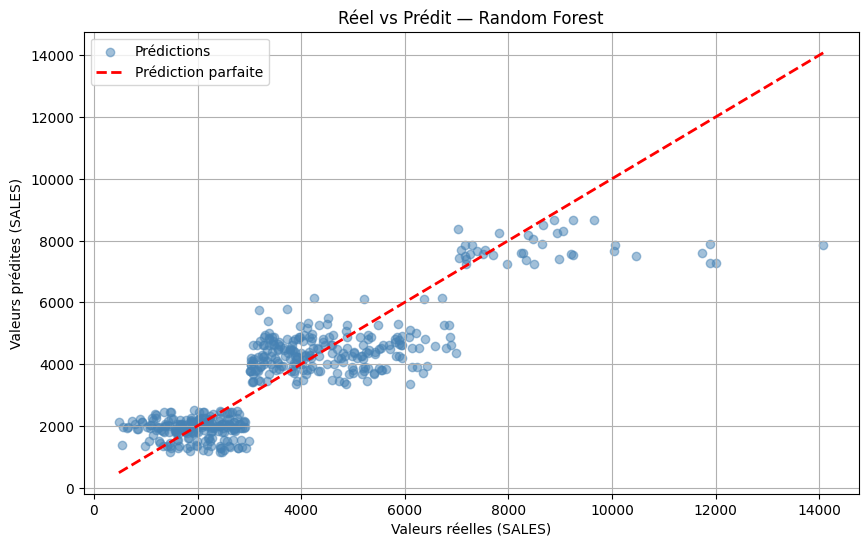

In [74]:
#Visualiser les prédictions vs réelles pour le Random Forest

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 6))

# Nuage de points : Réel vs Prédit
plt.scatter(y_test, y_pred_final, alpha=0.5, color="steelblue", label="Prédictions")

# Ligne de prédiction parfaite
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--', linewidth=2, label="Prédiction parfaite")

plt.xlabel("Valeurs réelles (SALES)")
plt.ylabel("Valeurs prédites (SALES)")
plt.title("Réel vs Prédit — Random Forest")
plt.legend()
plt.grid(True)
plt.show()

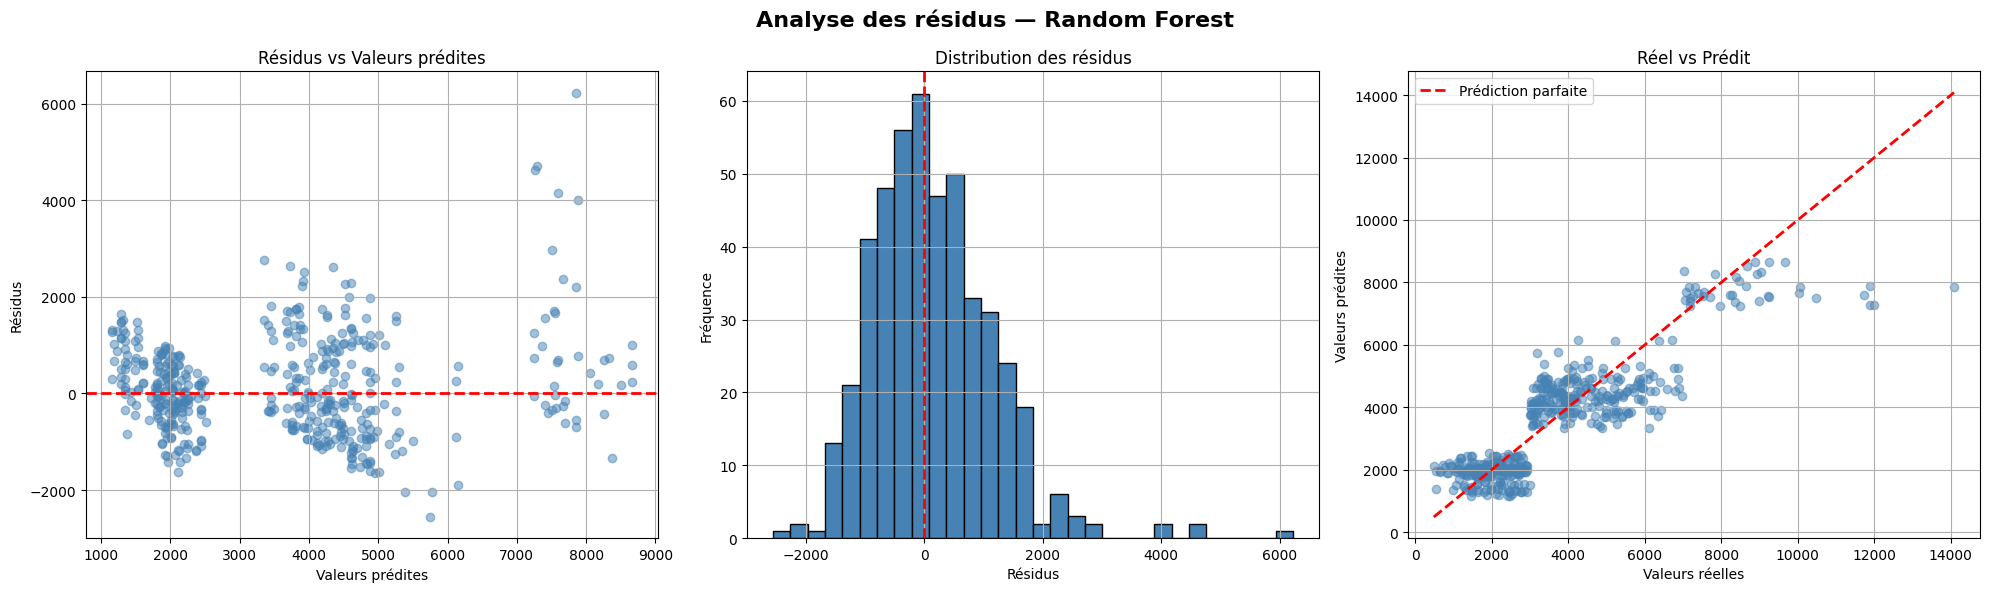

In [75]:
#Analyse des résidus pour le random forest 

import matplotlib.pyplot as plt
import numpy as np

# Calcul des résidus
residus = y_test - y_pred_final

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Analyse des résidus — Random Forest", fontsize=16, fontweight='bold')

# ========================
# 1. Résidus vs Valeurs prédites
# ========================
axes[0].scatter(y_pred_final, residus, alpha=0.5, color="steelblue")
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0].set_xlabel("Valeurs prédites")
axes[0].set_ylabel("Résidus")
axes[0].set_title("Résidus vs Valeurs prédites")
axes[0].grid(True)

# ========================
# 2. Distribution des résidus
# ========================
axes[1].hist(residus, bins=30, color="steelblue", edgecolor="black")
axes[1].axvline(x=0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel("Résidus")
axes[1].set_ylabel("Fréquence")
axes[1].set_title("Distribution des résidus")
axes[1].grid(True)

# ========================
# 3. Réel vs Prédit
# ========================
axes[2].scatter(y_test, y_pred_final, alpha=0.5, color="steelblue")
axes[2].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()],
             'r--', linewidth=2, label="Prédiction parfaite")
axes[2].set_xlabel("Valeurs réelles")
axes[2].set_ylabel("Valeurs prédites")
axes[2].set_title("Réel vs Prédit")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [76]:
#Comparer les prédictions
import pandas as pd

results = pd.DataFrame({
    "Valeur réelle": y_test,
    "LR Prediction": y_pred_lr,
    "RF prediction" : y_pred_final,
    "XGBoost prediction" : y_pred_xgb_log
})

results.head(10)

,Valeur réelle,LR Prediction,RF prediction,XGBoost prediction
2458,2577.60,2664.870353,2404.794440,2468.479736
2537,1463.00,2009.705053,2440.657739,2132.940918
2640,5192.64,4277.040840,4169.303387,4076.428955
2666,3789.72,4277.040840,4169.303387,4076.428955
2745,2116.16,2009.705053,2440.657739,2132.940918
146,2297.05,2876.511298,2396.857053,2496.081299
222,8470.14,8397.960975,8053.673221,7169.915039
423,3911.49,4717.669002,4243.385743,4239.862305
695,3949.00,4717.669002,4243.385743,4239.862305
746,2130.92,2450.333214,2020.282820,1870.865601


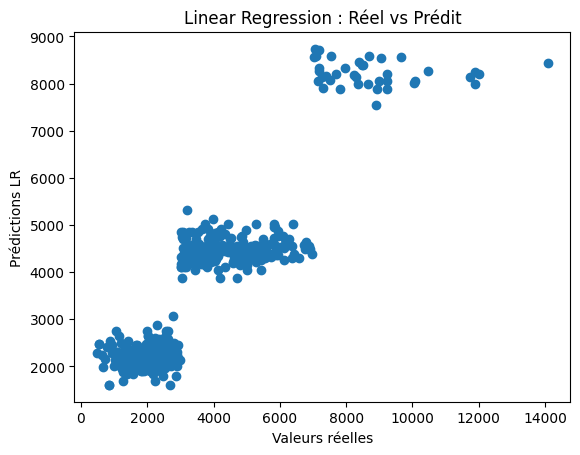

In [77]:
#Visualisation régression linéaire
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_lr)
plt.xlabel("Valeurs réelles")
plt.ylabel("Prédictions LR")
plt.title("Linear Regression : Réel vs Prédit")
plt.show()

In [78]:
#Comparaison des modèles
print("Linear Regression R2:", r2_score(y_test, y_pred_lr))
print("Random Forest R2:", r2_score(y_test, y_pred_final))

Linear Regression R2: 0.7880837289115473
Random Forest R2: 0.7639277041718644


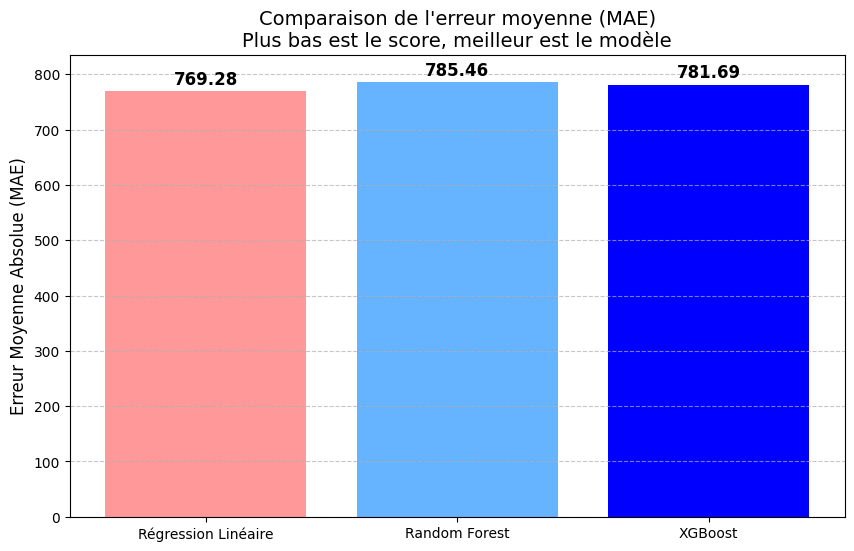

In [79]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcul direct des MAE pour chaque modèle
mae_lr  = mean_absolute_error(y_test, y_pred_lr)
mae_rf  = mean_absolute_error(y_test, y_pred_final)
mae_xgb = mean_absolute_error(y_test, y_pred_xgb_log)

modeles    = ['Régression Linéaire', 'Random Forest', 'XGBoost']
mae_values = [mae_lr, mae_rf, mae_xgb]

plt.figure(figsize=(10, 6))
bars = plt.bar(modeles, mae_values, color=['#ff9999', '#66b3ff', 'blue'])

# Ajout des étiquettes de score sur les barres
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, f'{yval:.2f}',
             ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.title('Comparaison de l\'erreur moyenne (MAE)\nPlus bas est le score, meilleur est le modèle', fontsize=14)
plt.ylabel('Erreur Moyenne Absolue (MAE)', fontsize=12)
plt.ylim(0, max(mae_values) + 50)  # S'adapte automatiquement aux valeurs
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

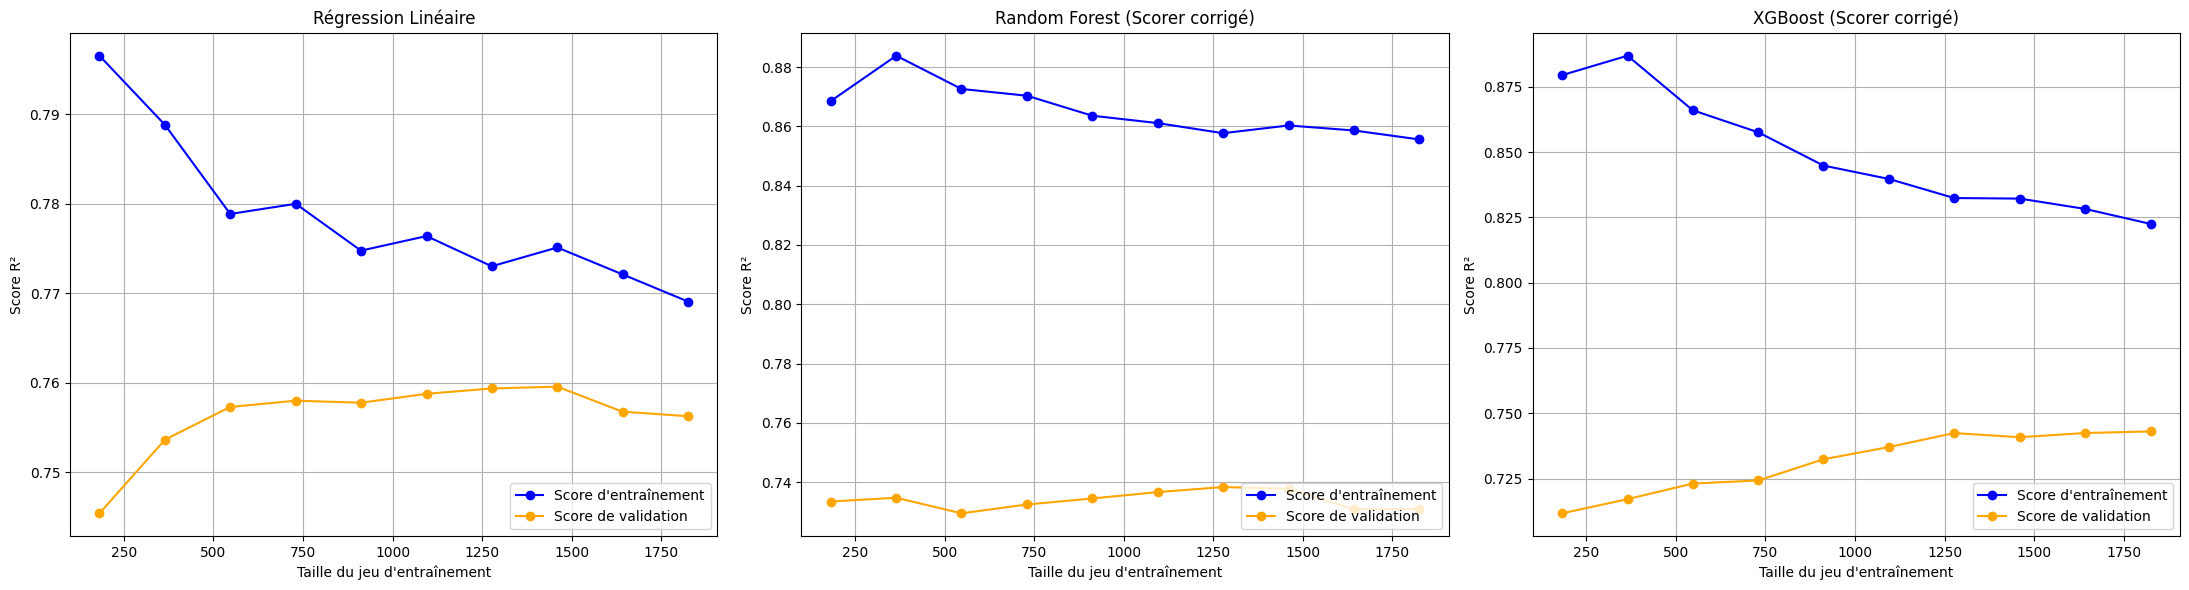

In [80]:
from sklearn.model_selection import learning_curve
from sklearn.metrics import make_scorer, r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
import matplotlib.pyplot as plt

# ========================
# Scorer personnalisé
# ========================
def r2_log_inverse(y_true, y_pred):
    return r2_score(np.expm1(y_true), np.expm1(y_pred))

scorer = make_scorer(r2_log_inverse)

# Transformation log1p sur y
y_train_log = np.log1p(y_train)



# ========================
# 1. Régression Linéaire
# ========================
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)



train_sizes_lr, train_scores_lr, test_scores_lr = learning_curve(
    lr, X_train, y_train, cv=5, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring='r2'
)

# ========================
# 2. Random Forest
# ========================
rf_log = RandomForestRegressor(n_estimators=100, random_state=42)

train_sizes_rf, train_scores_rf, test_scores_rf = learning_curve(
    rf_log, X_train, y_train_log, cv=5, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring=scorer
)

# ========================
# 3. XGBoost
# ========================
xgb_log = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

train_sizes_xgb, train_scores_xgb, test_scores_xgb = learning_curve(
    xgb_log, X_train, y_train_log, cv=5, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring=scorer
)

# ========================
# 4. Visualisation 3 graphiques
# ========================
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# Régression Linéaire
axes[0].plot(train_sizes_lr, np.mean(train_scores_lr, axis=1),
             'o-', color="blue", label="Score d'entraînement")
axes[0].plot(train_sizes_lr, np.mean(test_scores_lr, axis=1),
             'o-', color="orange", label="Score de validation")
axes[0].set_title("Régression Linéaire")
axes[0].set_xlabel("Taille du jeu d'entraînement")
axes[0].set_ylabel("Score R²")
axes[0].legend(loc="lower right")
axes[0].grid(True)

# Random Forest
axes[1].plot(train_sizes_rf, np.mean(train_scores_rf, axis=1),
             'o-', color="blue", label="Score d'entraînement")
axes[1].plot(train_sizes_rf, np.mean(test_scores_rf, axis=1),
             'o-', color="orange", label="Score de validation")
axes[1].set_title("Random Forest (Scorer corrigé)")
axes[1].set_xlabel("Taille du jeu d'entraînement")
axes[1].set_ylabel("Score R²")
axes[1].legend(loc="lower right")
axes[1].grid(True)

# XGBoost
axes[2].plot(train_sizes_xgb, np.mean(train_scores_xgb, axis=1),
             'o-', color="blue", label="Score d'entraînement")
axes[2].plot(train_sizes_xgb, np.mean(test_scores_xgb, axis=1),
             'o-', color="orange", label="Score de validation")
axes[2].set_title("XGBoost (Scorer corrigé)")
axes[2].set_xlabel("Taille du jeu d'entraînement")
axes[2].set_ylabel("Score R²")
axes[2].legend(loc="lower right")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [81]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# ========================
# 1. Séparation temporelle D'ABORD
# ========================
train_raw = df[df["YEAR"] < 2020].copy()
test_raw  = df[df["YEAR"] == 2020].copy()

# ========================
# 2. Features temporelles
# ========================
for dataset in [train_raw, test_raw]:
    dataset['QUARTER']   = pd.to_datetime(dataset['ORDERDATE']).dt.quarter
    dataset['FIN_ANNEE'] = dataset['MONTH'].apply(lambda x: 1 if x in [10, 11, 12] else 0)
    dataset['SAISON']    = dataset['MONTH'].apply(lambda x:
        'Hiver'     if x in [12, 1, 2] else
        'Printemps' if x in [3, 4, 5]  else
        'Ete'       if x in [6, 7, 8]  else 'Automne'
    )

# ========================
# 3. Stats calculées sur TRAIN uniquement
# ========================
client_stats = train_raw.groupby('CUSTOMERNAME')['SALES'].agg(
    SALES_MOYEN_CLIENT  = 'mean',
    SALES_TOTAL_CLIENT  = 'sum',
    NB_COMMANDES_CLIENT = 'count'
).reset_index()

produit_stats = train_raw.groupby('PRODUCTLINE')['SALES'].agg(
    SALES_MOYEN_PRODUIT = 'mean'
).reset_index()

dealsize_stats = train_raw.groupby('DEALSIZE')['SALES'].agg(
    SALES_MOYEN_DEALSIZE = 'mean'
).reset_index()

pays_stats = train_raw.groupby('COUNTRY')['SALES'].agg(
    SALES_MOYEN_PAYS   = 'mean',
    NB_COMMANDES_PAYS  = 'count'
).reset_index()

# ========================
# 4. Merger sur train ET test
# ========================
train_raw = train_raw.merge(client_stats,   on='CUSTOMERNAME', how='left')
train_raw = train_raw.merge(produit_stats,  on='PRODUCTLINE',  how='left')
train_raw = train_raw.merge(dealsize_stats, on='DEALSIZE',     how='left')
train_raw = train_raw.merge(pays_stats,     on='COUNTRY',      how='left')

test_raw  = test_raw.merge(client_stats,    on='CUSTOMERNAME', how='left')
test_raw  = test_raw.merge(produit_stats,   on='PRODUCTLINE',  how='left')
test_raw  = test_raw.merge(dealsize_stats,  on='DEALSIZE',     how='left')
test_raw  = test_raw.merge(pays_stats,      on='COUNTRY',      how='left')

# Vérification
print("Colonnes train_raw :", train_raw.shape)
print("Colonnes test_raw  :", test_raw.shape)

# Supprimer les colonnes _x et _y dupliquées
colonnes_x = [col for col in train_raw.columns if col.endswith('_x')]
colonnes_y = [col for col in train_raw.columns if col.endswith('_y')]

# Supprimer _y et renommer _x 
train_raw = train_raw.drop(columns=colonnes_y)
test_raw  = test_raw.drop(columns=colonnes_y)

train_raw.columns = [col.replace('_x', '') for col in train_raw.columns]
test_raw.columns  = [col.replace('_x', '') for col in test_raw.columns]

# Vérification
print("Colonnes train_raw :", train_raw.columns.tolist())

# ========================
# 5. Sélection des features
# ========================
features = [
    "DAYS_SINCE_LASTORDER", "PRODUCTLINE", "DEALSIZE",
    "COUNTRY", "STATUS", "MONTH", "YEAR",
    "QUARTER", "FIN_ANNEE", "SAISON",
    "SALES_MOYEN_CLIENT", "NB_COMMANDES_CLIENT", "SALES_TOTAL_CLIENT",
    "SALES_MOYEN_PRODUIT", "SALES_MOYEN_DEALSIZE",
    "SALES_MOYEN_PAYS", "NB_COMMANDES_PAYS"
]

train_model = train_raw[features + ["SALES"]]
test_model  = test_raw[features  + ["SALES"]]

# ========================
# 6. Encodage
# ========================
train_model = pd.get_dummies(train_model, columns=["PRODUCTLINE", "DEALSIZE", "COUNTRY", "STATUS", "SAISON"])
test_model  = pd.get_dummies(test_model,  columns=["PRODUCTLINE", "DEALSIZE", "COUNTRY", "STATUS", "SAISON"])

# Aligner les colonnes
test_model = test_model.reindex(columns=train_model.columns, fill_value=0)

# ========================
# 7. X et y
# ========================
X_train = train_model.drop(columns=["SALES"])
y_train = train_model["SALES"]
X_test  = test_model.drop(columns=["SALES"])
y_test  = test_model["SALES"]

print(f"\nX_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")

# ========================
# 8. Entraînement des 3 modèles
# ========================
y_train_log = np.log1p(y_train)

# Régression Linéaire
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# Random Forest
rf_log = RandomForestRegressor(
    n_estimators=500, min_samples_split=10,
    min_samples_leaf=5, max_features='sqrt',
    max_depth=15, random_state=42
)
rf_log.fit(X_train, y_train_log)
y_pred_rf = np.expm1(rf_log.predict(X_test))

# XGBoost
xgb_log = XGBRegressor(
    n_estimators=300, learning_rate=0.05,
    max_depth=5, subsample=0.8,
    colsample_bytree=0.8, random_state=42
)
xgb_log.fit(X_train, y_train_log)
y_pred_xgb = np.expm1(xgb_log.predict(X_test))

# ========================
# 9. Résultats
# ========================
print("\n=== Résultats après Feature Engineering ===")
print(f"{'Modèle':<25} {'R²':>8} {'MAE':>10}")
print("-" * 45)
print(f"{'Régression Linéaire':<25} {r2_score(y_test, y_pred_lr):>8.4f} {mean_absolute_error(y_test, y_pred_lr):>10.2f}")
print(f"{'Random Forest':<25} {r2_score(y_test, y_pred_rf):>8.4f} {mean_absolute_error(y_test, y_pred_rf):>10.2f}")
print(f"{'XGBoost':<25} {r2_score(y_test, y_pred_xgb):>8.4f} {mean_absolute_error(y_test, y_pred_xgb):>10.2f}")

print("\n=== Comparaison avant/après Feature Engineering ===")
print(f"{'Modèle':<25} {'R² avant':>10} {'R² après':>10} {'MAE avant':>10} {'MAE après':>10}")
print("-" * 47)
print(f"{'Régression Linéaire':<25} {'0.7881':>10} {r2_score(y_test, y_pred_lr):>10.4f} {'769.28':>10} {mean_absolute_error(y_test, y_pred_lr):>10.2f}")
print(f"{'Random Forest':<25} {'0.7611':>10} {r2_score(y_test, y_pred_rf):>10.4f} {'781.69':>10} {mean_absolute_error(y_test, y_pred_rf):>10.2f}")
print(f"{'XGBoost':<25} {'0.7582':>10} {r2_score(y_test, y_pred_xgb):>10.4f} {'785.46':>10} {mean_absolute_error(y_test, y_pred_xgb):>10.2f}")

Colonnes train_raw : (2282, 32)
Colonnes test_raw  : (465, 32)
Colonnes train_raw : ['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'DAYS_SINCE_LASTORDER', 'STATUS', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'CITY', 'POSTALCODE', 'COUNTRY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE', 'YEAR', 'MONTH', 'QUARTER', 'FIN_ANNEE', 'SAISON', 'SALES_MOYEN_CLIENT', 'SALES_TOTAL_CLIENT', 'NB_COMMANDES_CLIENT', 'SALES_MOYEN_PRODUIT', 'SALES_MOYEN_DEALSIZE', 'SALES_MOYEN_PAYS', 'NB_COMMANDES_PAYS']

X_train : (2282, 49)
X_test  : (465, 49)

=== Résultats après Feature Engineering ===
Modèle                          R²        MAE
---------------------------------------------
Régression Linéaire         0.7870     773.83
Random Forest               0.7469     778.96
XGBoost                     0.7789     758.17

=== Comparaison avant/après Feature Engineering ===
Modèle                      R² avant   R² après  MAE a

In [82]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

# Transformation log1p
y_train_log = np.log1p(y_train)

# Grille des hyperparamètres
param_grid = {
    'n_estimators'    : [100, 200, 300, 500],
    'learning_rate'   : [0.01, 0.05, 0.1, 0.2],
    'max_depth'       : [3, 4, 5, 6, 8],
    'subsample'       : [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5, 7],
    'gamma'           : [0, 0.1, 0.2, 0.3],
    'reg_alpha'       : [0, 0.01, 0.1, 1],
    'reg_lambda'      : [0.5, 1, 1.5, 2]
}

# Modèle de base
xgb = XGBRegressor(random_state=42, verbosity=0)

# Recherche aléatoire
xgb_random = RandomizedSearchCV(
    estimator           = xgb,
    param_distributions = param_grid,
    n_iter              = 50,
    cv                  = 5,
    scoring             = 'r2',
    n_jobs              = -1,
    random_state        = 42,
    verbose             = 1
)

# Entraînement
xgb_random.fit(X_train, y_train_log)

# Meilleurs hyperparamètres
print("\n=== Meilleurs hyperparamètres ===")
print(xgb_random.best_params_)

# Prédiction et inversion log1p
y_pred_xgb_opt = np.expm1(xgb_random.best_estimator_.predict(X_test))

# Résultats
print("\n=== Résultats après optimisation ===")
print(f"R²  : {r2_score(y_test, y_pred_xgb_opt):.4f}")
print(f"MAE : {mean_absolute_error(y_test, y_pred_xgb_opt):.2f}")

print("\n=== Comparaison avant/après optimisation ===")
print(f"R²  avant : 0.7789  →  après : {r2_score(y_test, y_pred_xgb_opt):.4f}")
print(f"MAE avant : 758.17  →  après : {mean_absolute_error(y_test, y_pred_xgb_opt):.2f}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits

=== Meilleurs hyperparamètres ===
{'subsample': 0.6, 'reg_lambda': 2, 'reg_alpha': 1, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.01, 'gamma': 0, 'colsample_bytree': 0.7}

=== Résultats après optimisation ===
R²  : 0.7777
MAE : 743.61

=== Comparaison avant/après optimisation ===
R²  avant : 0.7789  →  après : 0.7777
MAE avant : 758.17  →  après : 743.61


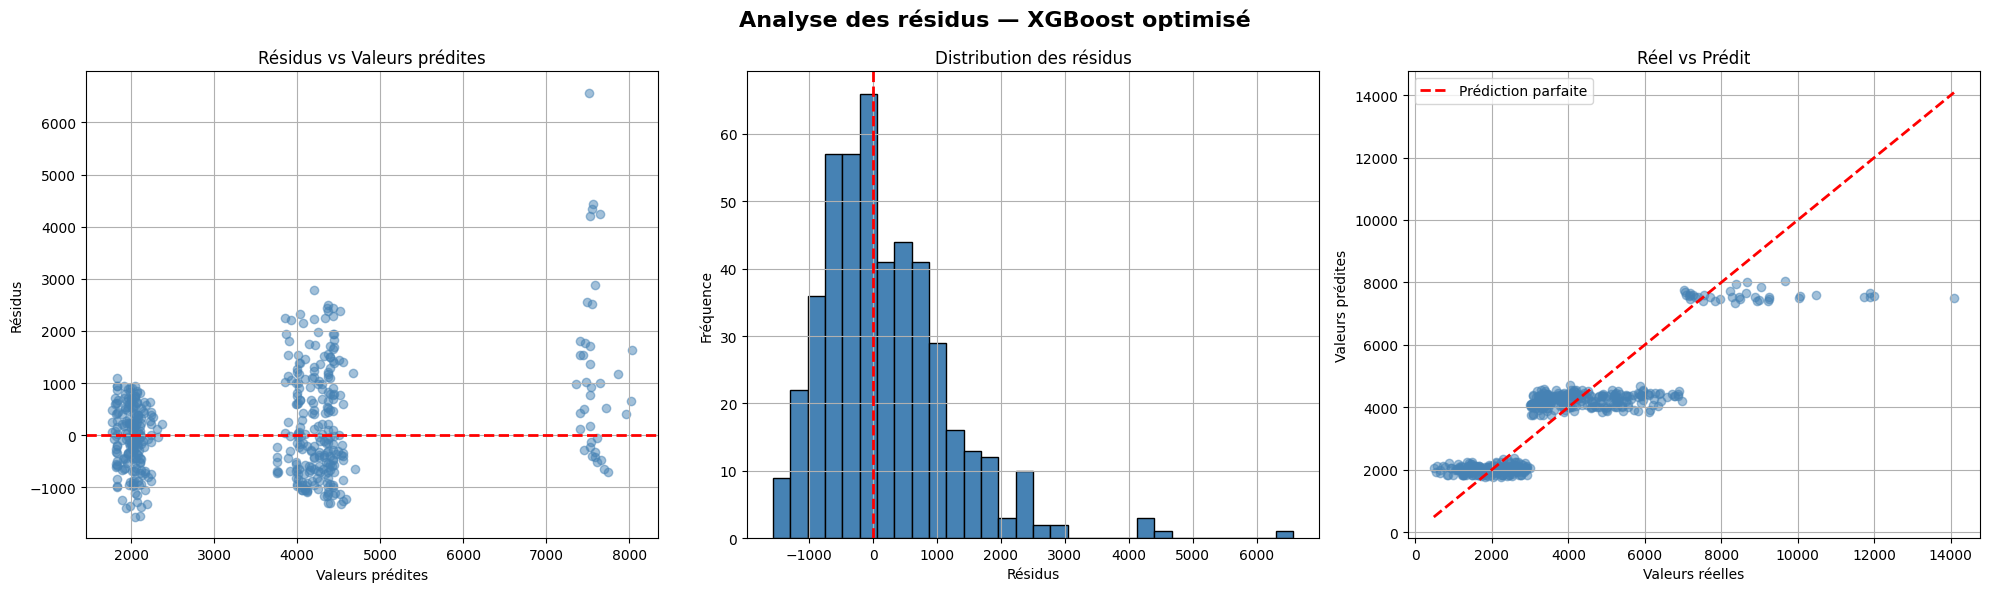

=== Statistiques des résidus ===
Moyenne    : 175.44$
Std        : 1001.45$
Min        : -1569.10$
Max        : 6572.53$
Médiane    : 10.37$


In [83]:
# Calcul des résidus
residus = y_test - y_pred_xgb_opt

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Analyse des résidus — XGBoost optimisé", fontsize=16, fontweight='bold')

# ========================
# 1. Résidus vs Valeurs prédites
# ========================
axes[0].scatter(y_pred_xgb_opt, residus, alpha=0.5, color="steelblue")
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0].set_xlabel("Valeurs prédites")
axes[0].set_ylabel("Résidus")
axes[0].set_title("Résidus vs Valeurs prédites")
axes[0].grid(True)

# ========================
# 2. Distribution des résidus
# ========================
axes[1].hist(residus, bins=30, color="steelblue", edgecolor="black")
axes[1].axvline(x=0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel("Résidus")
axes[1].set_ylabel("Fréquence")
axes[1].set_title("Distribution des résidus")
axes[1].grid(True)

# ========================
# 3. Réel vs Prédit
# ========================
axes[2].scatter(y_test, y_pred_xgb_opt, alpha=0.5, color="steelblue")
axes[2].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()],
             'r--', linewidth=2, label="Prédiction parfaite")
axes[2].set_xlabel("Valeurs réelles")
axes[2].set_ylabel("Valeurs prédites")
axes[2].set_title("Réel vs Prédit")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

# ========================
# 4. Statistiques des résidus
# ========================
print("=== Statistiques des résidus ===")
print(f"Moyenne    : {residus.mean():.2f}$")
print(f"Std        : {residus.std():.2f}$")
print(f"Min        : {residus.min():.2f}$")
print(f"Max        : {residus.max():.2f}$")
print(f"Médiane    : {residus.median():.2f}$")

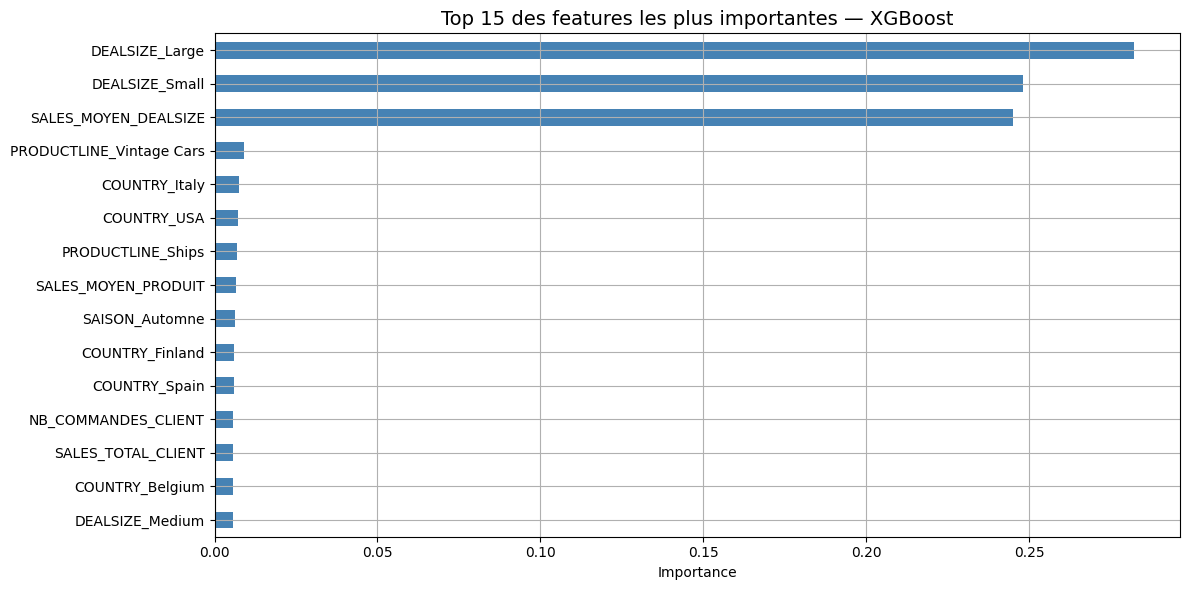

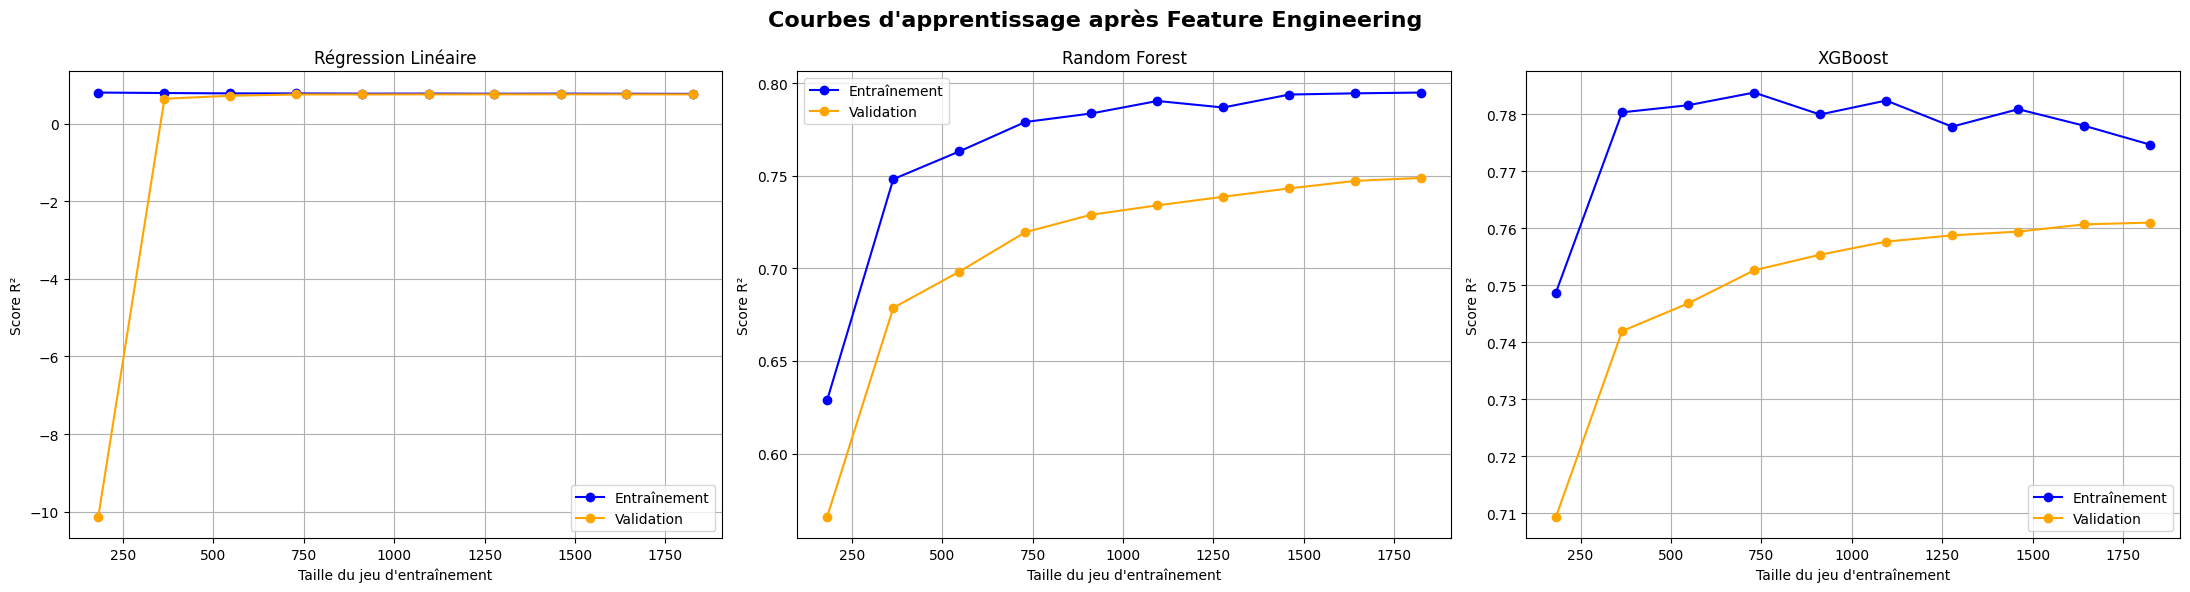

In [84]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import learning_curve
from sklearn.metrics import make_scorer, r2_score

# ========================
# 1. Importance des features
# ========================
importances = pd.Series(
    xgb_log.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False).head(15)

plt.figure(figsize=(12, 6))
importances.plot(kind="barh", color="steelblue")
plt.title("Top 15 des features les plus importantes — XGBoost", fontsize=14)
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.grid(True)
plt.tight_layout()
plt.show()

# ========================
# 2. Courbes d'apprentissage
# ========================
def r2_log_inverse(y_true, y_pred):
    return r2_score(np.expm1(y_true), np.expm1(y_pred))

scorer = make_scorer(r2_log_inverse)
y_train_log = np.log1p(y_train)

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
fig.suptitle("Courbes d'apprentissage après Feature Engineering", fontsize=16, fontweight='bold')

# Régression Linéaire
from sklearn.linear_model import LinearRegression
lr_sizes, lr_train, lr_test = learning_curve(
    LinearRegression(), X_train, y_train,
    cv=5, n_jobs=-1, scoring='r2',
    train_sizes=np.linspace(0.1, 1.0, 10)
)
axes[0].plot(lr_sizes, np.mean(lr_train, axis=1), 'o-', color="blue",   label="Entraînement")
axes[0].plot(lr_sizes, np.mean(lr_test,  axis=1), 'o-', color="orange", label="Validation")
axes[0].set_title("Régression Linéaire")
axes[0].set_xlabel("Taille du jeu d'entraînement")
axes[0].set_ylabel("Score R²")
axes[0].legend()
axes[0].grid(True)

# Random Forest
from sklearn.ensemble import RandomForestRegressor
rf_sizes, rf_train, rf_test = learning_curve(
    RandomForestRegressor(n_estimators=500, min_samples_split=10,
    min_samples_leaf=5, max_features='sqrt',
    max_depth=15, random_state=42),
    X_train, y_train_log,
    cv=5, n_jobs=-1, scoring=scorer,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
axes[1].plot(rf_sizes, np.mean(rf_train, axis=1), 'o-', color="blue",   label="Entraînement")
axes[1].plot(rf_sizes, np.mean(rf_test,  axis=1), 'o-', color="orange", label="Validation")
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Taille du jeu d'entraînement")
axes[1].set_ylabel("Score R²")
axes[1].legend()
axes[1].grid(True)

# XGBoost
from xgboost import XGBRegressor
xgb_sizes, xgb_train, xgb_test = learning_curve(
    XGBRegressor(n_estimators=500, learning_rate=0.01, max_depth=3,
                 subsample=0.6, colsample_bytree=0.7, random_state=42, min_child_weight=5,  reg_lambda=2, reg_alpha=1, gamma=0),
    X_train, y_train_log,
    cv=5, n_jobs=-1, scoring=scorer,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
axes[2].plot(xgb_sizes, np.mean(xgb_train, axis=1), 'o-', color="blue",   label="Entraînement")
axes[2].plot(xgb_sizes, np.mean(xgb_test,  axis=1), 'o-', color="orange", label="Validation")
axes[2].set_title("XGBoost")
axes[2].set_xlabel("Taille du jeu d'entraînement")
axes[2].set_ylabel("Score R²")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [ ]:

import pandas as pd
import numpy as np
import joblib
from pathlib import Path

from xgboost import XGBRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error

# =====================================================
# 1. PREPARATION ET SEPARATION TEMPORELLE
# =====================================================

data = df.copy()
data["ORDERDATE"] = pd.to_datetime(data["ORDERDATE"], errors="coerce")

# Vérification des données essentielles
data = data.dropna(subset=["ORDERDATE", "SALES"]).copy()

if (data["SALES"] < 0).any():
    raise ValueError(
        "La cible SALES contient des valeurs négatives : "
        "vérifie les données avant d'utiliser log1p."
    )

data["YEAR"] = data["ORDERDATE"].dt.year
data["MONTH"] = data["ORDERDATE"].dt.month

train_raw = data[data["YEAR"] < 2020].copy()
test_raw = data[data["YEAR"] == 2020].copy()

if train_raw.empty or test_raw.empty:
    raise ValueError(
        "Le dataset doit contenir des ventes avant 2020 "
        "et des ventes en 2020."
    )

# =====================================================
# 2. VARIABLES TEMPORELLES
# =====================================================

def add_features(dataframe):
    result = dataframe.copy()

    result["QUARTER"] = result["ORDERDATE"].dt.quarter
    result["FIN_ANNEE"] = (
        result["MONTH"].isin([10, 11, 12]).astype(int)
    )

    result["SAISON"] = result["MONTH"].map({
        12: "Hiver", 1: "Hiver", 2: "Hiver",
        3: "Printemps", 4: "Printemps", 5: "Printemps",
        6: "Ete", 7: "Ete", 8: "Ete",
        9: "Automne", 10: "Automne", 11: "Automne"
    })

    return result


train_raw = add_features(train_raw)
test_raw = add_features(test_raw)

# Conserver les données d'entraînement sans statistiques calculées.
# Elles serviront de référence historique pour le train et le test.
train_historique = train_raw.copy()

# =====================================================
# 3. STATISTIQUES HISTORIQUES SANS FUITE DE DONNEES
# =====================================================

colonnes_stats = [
    "SALES_MOYEN_CLIENT",
    "SALES_TOTAL_CLIENT",
    "SALES_MOYEN_PRODUIT",
    "SALES_MOYEN_DEALSIZE",
    "SALES_MOYEN_PAYS",
]


def calculer_stats_historiques(historique, commandes):
    """
    Pour chaque date de commande, calcule les statistiques
    uniquement à partir des ventes strictement antérieures.

    Les ventes du même jour ne sont pas utilisées.
    """

    historique = historique.copy()
    commandes = commandes.copy()

    historique["ORDERDATE"] = pd.to_datetime(
        historique["ORDERDATE"]
    )
    commandes["ORDERDATE"] = pd.to_datetime(
        commandes["ORDERDATE"]
    )

    commandes["__ordre_original"] = np.arange(len(commandes))
    resultat = []

    for date_commande, groupe in commandes.groupby(
        "ORDERDATE", sort=True
    ):
        passe = historique[
            historique["ORDERDATE"] < date_commande
        ]

        lignes = groupe.copy()

        client = passe.groupby("CUSTOMERNAME")["SALES"].agg(
            SALES_MOYEN_CLIENT="mean",
            SALES_TOTAL_CLIENT="sum",
        )

        produit = passe.groupby("PRODUCTLINE")["SALES"].mean()
        taille = passe.groupby("DEALSIZE")["SALES"].mean()
        pays = passe.groupby("COUNTRY")["SALES"].mean()

        lignes["SALES_MOYEN_CLIENT"] = (
            lignes["CUSTOMERNAME"].map(
                client["SALES_MOYEN_CLIENT"]
            )
        )
        lignes["SALES_TOTAL_CLIENT"] = (
            lignes["CUSTOMERNAME"].map(
                client["SALES_TOTAL_CLIENT"]
            )
        )
        lignes["SALES_MOYEN_PRODUIT"] = (
            lignes["PRODUCTLINE"].map(produit)
        )
        lignes["SALES_MOYEN_DEALSIZE"] = (
            lignes["DEALSIZE"].map(taille)
        )
        lignes["SALES_MOYEN_PAYS"] = (
            lignes["COUNTRY"].map(pays)
        )

        lignes[colonnes_stats] = (
            lignes[colonnes_stats].fillna(0)
        )

        resultat.append(lignes)

    if not resultat:
        commandes[colonnes_stats] = 0.0
        return commandes.drop(
            columns=["__ordre_original"]
        )

    resultat = pd.concat(resultat, ignore_index=True)
    resultat = resultat.sort_values("__ordre_original")

    return resultat.drop(columns=["__ordre_original"])


# Une seule application pour le train et une pour le test.
# Le test utilise uniquement l'historique d'entraînement.
train_raw = calculer_stats_historiques(
    historique=train_historique,
    commandes=train_historique
)

test_raw = calculer_stats_historiques(
    historique=train_historique,
    commandes=test_raw
)

# =====================================================
# 4. PREPARATION DE X_train, X_test, y_train ET y_test
# =====================================================

# Garder ces variables cohérentes avec l'API actuelle.
categorical_features = [
    "PRODUCTLINE",
    "DEALSIZE",
    "COUNTRY",
    "STATUS",
    "SAISON",
]

numeric_features = [
    "MONTH",
    "YEAR",
    "QUARTER",
    "FIN_ANNEE",
    "SALES_MOYEN_CLIENT",
    "SALES_TOTAL_CLIENT",
    "SALES_MOYEN_PRODUIT",
    "SALES_MOYEN_DEALSIZE",
    "SALES_MOYEN_PAYS",
]

feature_cols = categorical_features + numeric_features

# Vérifier que toutes les variables attendues existent.
for nom, dataframe in [
    ("train_raw", train_raw),
    ("test_raw", test_raw),
]:
    manquantes = [
        col for col in feature_cols
        if col not in dataframe.columns
    ]

    if manquantes:
        raise ValueError(
            f"Colonnes manquantes dans {nom} : {manquantes}"
        )

X_train = train_raw[feature_cols].copy()
y_train = train_raw["SALES"].copy()

X_test = test_raw[feature_cols].copy()
y_test = test_raw["SALES"].copy()

# Harmoniser les catégories et traiter les valeurs manquantes.
for col in categorical_features:
    X_train[col] = X_train[col].fillna("Inconnu").astype(str)
    X_test[col] = X_test[col].fillna("Inconnu").astype(str)

for col in numeric_features:
    X_train[col] = pd.to_numeric(
        X_train[col], errors="coerce"
    ).fillna(0)

    X_test[col] = pd.to_numeric(
        X_test[col], errors="coerce"
    ).fillna(0)

print("Nombre de lignes train :", len(X_train))
print("Nombre de lignes test  :", len(X_test))
print("Variables utilisées    :", feature_cols)

# =====================================================
# 5. PREPROCESSEUR ET MODELE XGBOOST
# =====================================================

preprocess = ColumnTransformer([
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features,
    ),
    (
        "num",
        "passthrough",
        numeric_features,
    ),
])

model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.01,
    max_depth=3,
    subsample=0.6,
    colsample_bytree=0.7,
    random_state=42,
    min_child_weight=5,
    reg_lambda=2,
    reg_alpha=1,
    objective="reg:squarederror",
    eval_metric="mae",
    n_jobs=-1,
)

pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", model),
])

# Entraînement sur le logarithme des ventes.
pipeline.fit(X_train, np.log1p(y_train))

# =====================================================
# 6. EVALUATION
# =====================================================

pred = np.maximum(
    0,
    np.expm1(pipeline.predict(X_test))
)

print("\n===== RESULTATS DU MODELE =====")
print(f"R²  : {r2_score(y_test, pred):.4f}")
print(f"MAE : {mean_absolute_error(y_test, pred):.2f}")

# =====================================================
# 7. SAUVEGARDE DU PIPELINE
# =====================================================

# Enregistrer à la racine du projet.
cwd = Path.cwd()

if cwd.name.lower() == "notebooks":
    root_dir = cwd.parent
elif (cwd / "notebooks").is_dir():
    root_dir = cwd
else:
    root_dir = cwd

model_dir = root_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "sales_pipeline.pkl"

joblib.dump(pipeline, model_path)

print(f"\nPipeline sauvegardé : {model_path.resolve()}")


Nombre de lignes train : 2282
Nombre de lignes test  : 465
Variables utilisées    : ['PRODUCTLINE', 'DEALSIZE', 'COUNTRY', 'STATUS', 'SAISON', 'MONTH', 'YEAR', 'QUARTER', 'FIN_ANNEE', 'SALES_MOYEN_CLIENT', 'SALES_TOTAL_CLIENT', 'SALES_MOYEN_PRODUIT', 'SALES_MOYEN_DEALSIZE', 'SALES_MOYEN_PAYS']

===== RESULTATS DU MODELE =====
R²  : 0.7794
MAE : 748.58

Pipeline sauvegardé : C:\Users\DC\Projects\Predict_Sales\models\sales_pipeline.pkl
